# Dichotic right: overt and masked onsets, intensity-level control

Part of the per-condition split of `cortical_analysis.ipynb`; runs on its own.
Shared settings (models, fit parameters, ROI, peak windows, plot window) are in
`parameters.py`.

**Results come from the cluster.** Every fit and model test is computed and kept on the
cluster; this notebook only reads them and saves nothing. In the cluster's JupyterHub
(any browser, laptop closed) it reads them from the cluster's disk; on the Mac (VS Code or
Jupyter), open the connection once in a terminal with `bash cluster/connect.sh`. The
`check_results` cell below asks the cluster for anything missing by itself, waits for the job
and then carries on, so one Run All goes from start to finish (keep the computer awake). See `cluster/README.md`.

**Model comparisons:** TFCE permutation tests within the ROI found in the clean notebook
(`roi.txt`, read by the `check_results` cell; `TEST_REGION` in `parameters.py`), as
Brodbeck et al. 2020 did for the two-talker conditions.

**Peaks:** each subject's peak is searched within +-25 ms of where that condition's
group-average waveform peaks inside the search window (`add_anchored_peak`).

**Per-bin TRF plots** (`plot_trf_bins`): one line per frequency bin in its own colour
with a band of +-1 SEM across subjects (`BIN_ERROR` in `parameters.py`), the mean of
the bins as the thick black line, and the bins' centre frequencies on the right.

In [1]:
from parameters import *

In [2]:
# Checks that every result this notebook reads is on the cluster. If any are missing it
# asks the cluster for them, waits for the job (a line whenever its state changes) and
# carries on. Keep the computer awake while it waits.
check_results('dichotic_right_overt_masked_onsets')

7 of 7 results this notebook reads are not on the cluster yet; asking the cluster for them.
Submitted job 9239220 for dichotic_right_overt_masked_onsets. Follow it with cluster_queue(); the cluster also emails when it ends.
Waiting for job 9239220 (checked every minute; the cluster also emails when it ends). Interrupting only stops the waiting, not the job.
  22:21  9239220 pending  (0 min so far)
  22:28  9239220 running  (7 min so far)
Job 9239220 is done: all 7 results are on the cluster. Carrying on with the notebook.


In [3]:
# Your cluster jobs (PD = waiting for a slot, R = running).
cluster_queue()

          JOBID     USER      ACCOUNT           NAME  ST  TIME_LEFT NODES CPUS TRES_PER_N MIN_MEM NODELIST (REASON) 
        9239211     iggy def-ibruce_c cocktail-dicho   R 1-23:25:36     1   32        N/A    128G nc30411 (None) 
        9239234     iggy def-ibruce_c cocktail-dicho   R 1-23:27:57     1   32        N/A    128G nc10454 (None) 
        9239240     iggy def-ibruce_c cocktail-dicho   R 1-23:28:04     1   32        N/A    128G nc30430 (None) 



In [4]:
# The end of the latest cluster job's log (or cluster_log(<job number>)).
cluster_log()

== cocktail-dichotic_right_overt_masked_onsets-9239220.out
INFO    :  *** BinauralCocktail initialized with root /lustre06/project/6005583/iggy/dataset/cocktail/bids on 2026-11-12 22:29:51 ***
INFO    :  Using eelbrain 0.0.0, mne 1.13.2.
INFO    :  *** BinauralCocktail initialized with root /lustre06/project/6005583/iggy/dataset/cocktail/bids on 2026-11-12 22:30:35 ***
INFO    :  Using eelbrain 0.0.0, mne 1.13.2.
  bad-channels file already exists for: 01, 02, 03, 04, 05, 06, 07, 08, 09, 10, 11, 12, 13. Skip all of them (default) or redo and overwrite all of them? [s/r]: s  (COCKTAIL_ANSWER)
  skipping (already done): 01, 02, 03, 04, 05, 06, 07, 08, 09, 10, 11, 12, 13

Done. Bad channels marked.
  ICA file already exists for: 01, 02, 03, 04, 05, 06, 07, 08, 09, 10, 11, 12, 13. Skip all of them (default) or redo and overwrite all of them? [s/r]: s  (COCKTAIL_ANSWER)
  skipping (already done): 01, 02, 03, 04, 05, 06, 07, 08, 09, 10, 11, 12, 13

Done. ICA fit and artifact components selec

## Dichotic Right (overt onsets)

In [ ]:
# The ROI this notebook uses, imported from roi.txt: the clean-speech notebook found it
# from its onset and envelope test - baseline topomaps.
ROI = show_roi('dichotic_right_overt_masked_onsets')

/Users/joshuaighalo/Github Repositories/cocktail-cortical/analysis/experiment.py:1063: UserWarning: Warning: converting a masked element to nan.
  mean_value = float(data.mean())


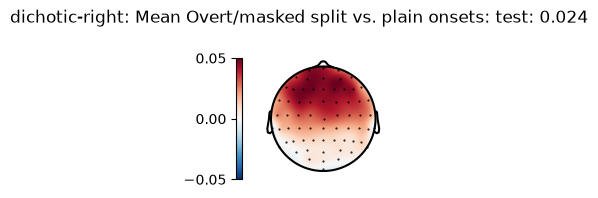

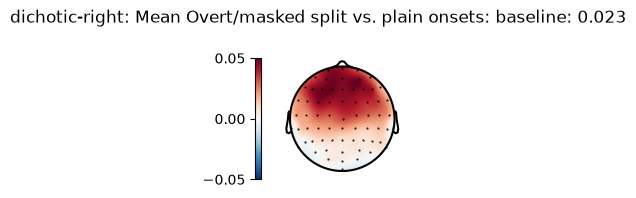

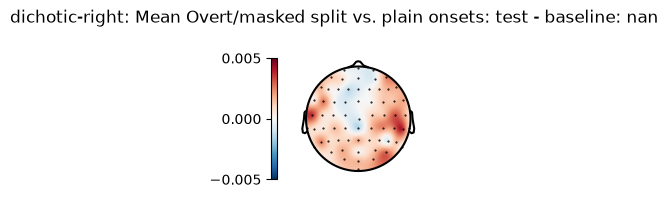

In [5]:
# Overt/masked split vs. plain onsets (dichotic-right)
# Brodbeck et al. 2020 ran this comparison too: splitting onsets into overt/masked significantly improved the model overall, t = 6.81, p < .001.
data, diff, result = compute_direct_comparison(FULL_MASKED, FULL_BASE, 'dichotic-right')
show_topomap_trio(data, diff, result, 'Overt/masked split vs. plain onsets', 'dichotic-right', None)

In [6]:
display(result)
ttest = test.TTestOneSample(f'roi_{METRIC}', data=diff, tail=1)
print(f"Overt/masked split vs. plain onsets (dichotic-right): ROI model comparison t({ttest.df}) = {ttest.t:.3f}, p = {ttest.p:.4f}")

<TTestRelated 'r', 'model', 'test', 'baseline', 'subject' (n=13), tail=1, samples=8191, pmin=0.05, 5 clusters, p = .326>

Overt/masked split vs. plain onsets (dichotic-right): ROI model comparison t(12) = 0.925, p = 0.1866


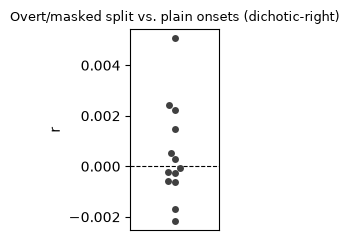

In [7]:
p = show_subject_swarm(diff, 'Overt/masked split vs. plain onsets', 'dichotic-right')

In [8]:
# Loaded once here, reused by every STRF/peak/waveform/attention-
# effect/masking-comparison cell in both this subsection and "masked
# onset" below - same reasoning as data_full above, for FULL_MASKED.
data_masked = load_trfs_saved(FULL_MASKED, 'dichotic-right')

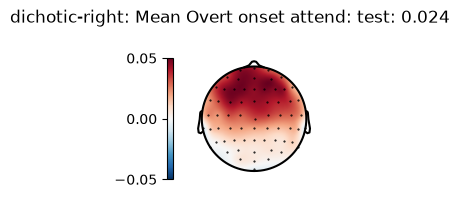

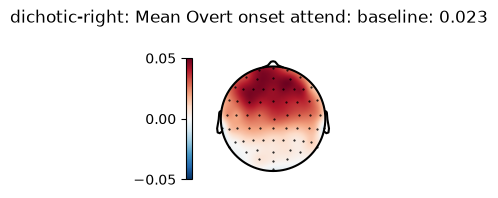

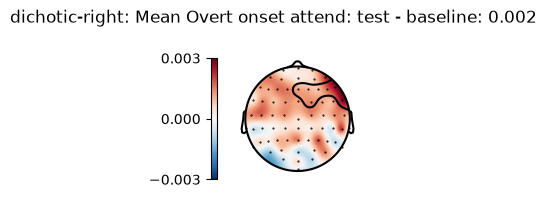

In [9]:
# Overt onset attend unique contribution (dichotic-right)
# Brodbeck et al. 2020 ran this comparison too: attended overt onsets unique contribution, t = 3.34, p = .027.
data, diff, result = compute_unique_contribution(FULL_MASKED, overt_onset(ATTEND), 'dichotic-right')
show_topomap_trio(data, diff, result, 'Overt onset attend', 'dichotic-right', overt_onset(ATTEND))

In [10]:
display(result)
ttest = test.TTestOneSample(f'roi_{METRIC}', data=diff, tail=1)
print(f"Overt onset attend (dichotic-right): ROI unique contribution t({ttest.df}) = {ttest.t:.3f}, p = {ttest.p:.4f}")

<TTestRelated 'r', 'model', 'test', 'baseline', 'subject' (n=13), tail=1, samples=8191, pmin=0.05, 6 clusters, p = .043>

Overt onset attend (dichotic-right): ROI unique contribution t(12) = 2.310, p = 0.0197


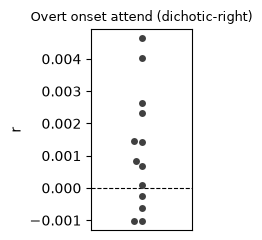

In [11]:
p = show_subject_swarm(diff, 'Overt onset attend', 'dichotic-right')

/Users/joshuaighalo/Github Repositories/cocktail-cortical/analysis/experiment.py:1063: UserWarning: Warning: converting a masked element to nan.
  mean_value = float(data.mean())


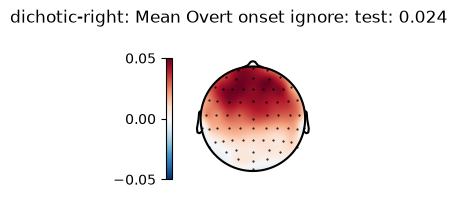

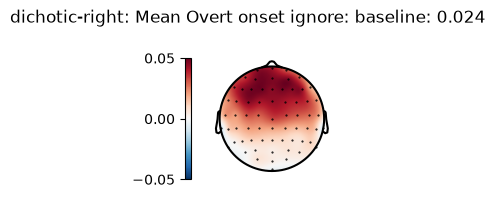

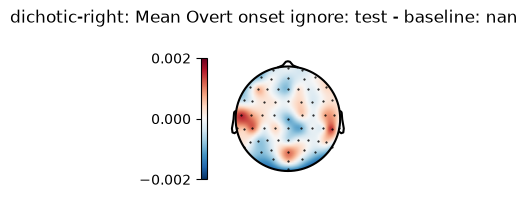

In [12]:
# Overt onset ignore unique contribution (dichotic-right)
# Brodbeck et al. 2020 ran this comparison too: ignored overt onsets unique contribution, t = 3.82, p = .016.
data, diff, result = compute_unique_contribution(FULL_MASKED, overt_onset(IGNORE), 'dichotic-right')
show_topomap_trio(data, diff, result, 'Overt onset ignore', 'dichotic-right', overt_onset(IGNORE))

In [13]:
display(result)
ttest = test.TTestOneSample(f'roi_{METRIC}', data=diff, tail=1)
print(f"Overt onset ignore (dichotic-right): ROI unique contribution t({ttest.df}) = {ttest.t:.3f}, p = {ttest.p:.4f}")

<TTestRelated 'r', 'model', 'test', 'baseline', 'subject' (n=13), tail=1, samples=8191, pmin=0.05, 1 clusters, p = .761>

Overt onset ignore (dichotic-right): ROI unique contribution t(12) = 0.048, p = 0.4812


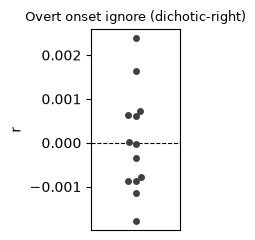

In [14]:
p = show_subject_swarm(diff, 'Overt onset ignore', 'dichotic-right')

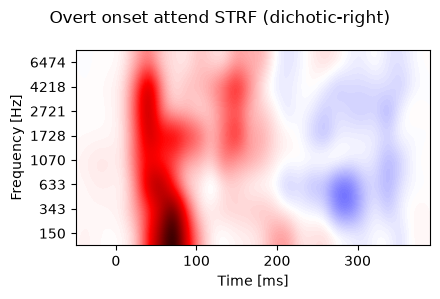

In [15]:
# Overt onset attend STRF (dichotic-right)
strf = extract_strf(data_masked, 'gammatone_on_overt_8')
p = plot.Array(strf * 1e3, title='Overt onset attend STRF (dichotic-right)', interpolation=STRF_INTERPOLATION, xlim=PLOT_WINDOW)

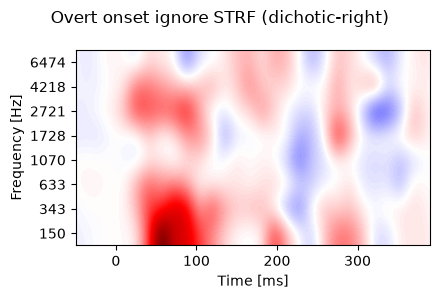

In [16]:
# Overt onset ignore STRF (dichotic-right)
strf = extract_strf(data_masked, 'bg_gammatone_on_overt_8')
p = plot.Array(strf * 1e3, title='Overt onset ignore STRF (dichotic-right)', interpolation=STRF_INTERPOLATION, xlim=PLOT_WINDOW)

In [17]:
# Overt onset attend peak amplitude & timing (dichotic-right)
data = extract_trf(data_masked, 'gammatone_on_overt_8')
data = add_anchored_peak(data, 'positive', ONSET_POSITIVE_PEAK_WINDOW, kind='max')
data = add_anchored_peak(data, 'negative', ONSET_NEGATIVE_PEAK_WINDOW, kind='min')
print(f"Overt onset attend (dichotic-right) positive peak: {data['positive_time'].mean() * 1e3:.0f} ms, amp {data['positive_amp'].mean():.4g}")
print(f"Overt onset attend (dichotic-right) negative peak: {data['negative_time'].mean() * 1e3:.0f} ms, amp {data['negative_amp'].mean():.4g}")

Overt onset attend (dichotic-right) positive peak: 52 ms, amp 0.003924
Overt onset attend (dichotic-right) negative peak: 193 ms, amp 6.91e-05


/Users/joshuaighalo/Github Repositories/cocktail-cortical/analysis/experiment.py:1798: UserWarning: negative anchor (all) at 199 ms is on the edge of the search window (0.04, 0.2)
  warnings.warn(f"{name} anchor ({label}) at {times[i] * 1e3:.0f} ms is on the edge of the search window {window}")


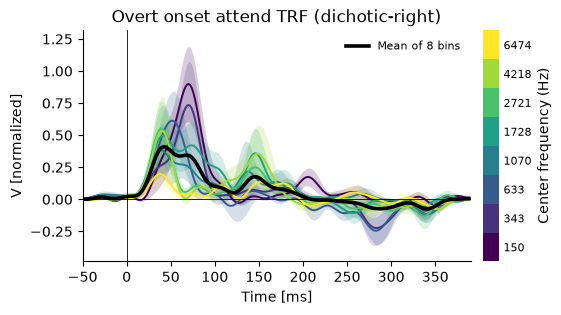

In [18]:
# Overt onset attend TRF per frequency bin (dichotic-right)
p = plot_trf_bins(data_masked, 'gammatone_on_overt_8', 'Overt onset attend TRF (dichotic-right)')

In [19]:
# Overt onset ignore peak amplitude & timing (dichotic-right)
data = extract_trf(data_masked, 'bg_gammatone_on_overt_8')
data = add_anchored_peak(data, 'positive', ONSET_POSITIVE_PEAK_WINDOW, kind='max')
data = add_anchored_peak(data, 'negative', ONSET_NEGATIVE_PEAK_WINDOW, kind='min')
print(f"Overt onset ignore (dichotic-right) positive peak: {data['positive_time'].mean() * 1e3:.0f} ms, amp {data['positive_amp'].mean():.4g}")
print(f"Overt onset ignore (dichotic-right) negative peak: {data['negative_time'].mean() * 1e3:.0f} ms, amp {data['negative_amp'].mean():.4g}")

Overt onset ignore (dichotic-right) positive peak: 62 ms, amp 0.001466
Overt onset ignore (dichotic-right) negative peak: 133 ms, amp -0.0002117


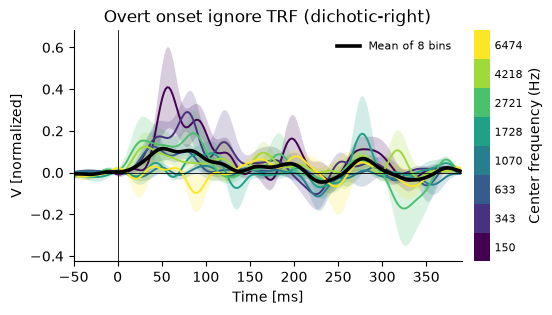

In [20]:
# Overt onset ignore TRF per frequency bin (dichotic-right)
p = plot_trf_bins(data_masked, 'bg_gammatone_on_overt_8', 'Overt onset ignore TRF (dichotic-right)')

In [21]:
# Overt onset peak comparison across attend and ignore (dichotic-right)
dss = []
for role_name, column in (('attend', 'gammatone_on_overt_8'), ('ignore', 'bg_gammatone_on_overt_8')):
    ds = extract_trf(data_masked, column)
    ds[:, 'role'] = role_name
    dss.append(ds)
data = combine(dss)
data = add_anchored_peak(data, 'positive', ONSET_POSITIVE_PEAK_WINDOW, kind='max', by='role')
data = add_anchored_peak(data, 'negative', ONSET_NEGATIVE_PEAK_WINDOW, kind='min', by='role')

/Users/joshuaighalo/Github Repositories/cocktail-cortical/analysis/experiment.py:1798: UserWarning: negative anchor (attend) at 199 ms is on the edge of the search window (0.04, 0.2)
  warnings.warn(f"{name} anchor ({label}) at {times[i] * 1e3:.0f} ms is on the edge of the search window {window}")


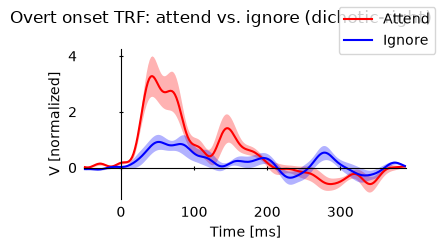

In [22]:
# The overt onset TRF waveform attend/ignore were each just measured
# from, overlaid so their shape and relative timing are visible
# directly, not just as extracted peak numbers below.
p = plot.UTSStat('trf_sm*1e3', 'role', data=data, frame='t', h=2.5, w=4, xlim=PLOT_WINDOW,
                  title='Overt onset TRF: attend vs. ignore (dichotic-right)', labels={'attend': 'Attend', 'ignore': 'Ignore'}, colors={'attend': 'red', 'ignore': 'blue'})

In [23]:
print_peak_table(data, 'positive', 'role')
print_peak_table(data, 'negative', 'role')


positive peak
subject   role         time (ms)           amp
01        attend              46     0.0008426
02        attend              56      0.004289
03        attend              41      0.001667
04        attend              62     0.0004542
05        attend              41      0.007624
06        attend              43      0.001422
07        attend              66       0.00152
08        attend              45      0.005802
09        attend              66      0.008882
10        attend              43      0.007422
11        attend              66      0.003017
12        attend              41      0.005783
13        attend              66       0.00229
01        ignore              54     0.0006277
02        ignore              76      0.001144
03        ignore              76     0.0003953
04        ignore              58       0.00185
05        ignore              56      0.002913
06        ignore              41     0.0004993
07        ignore              76      0.00195

In [24]:
display(test.pairwise('positive_time', 'role', match='subject', data=data, corr=False, title='overt onset positive peak latency: attend vs. ignore'))
display(test.pairwise('negative_time', 'role', match='subject', data=data, corr=False, title='overt onset negative peak latency: attend vs. ignore'))

,ignore
attend,t12 = -2.18* p = .049


,ignore
attend,t12 = 11.03*** p < .001


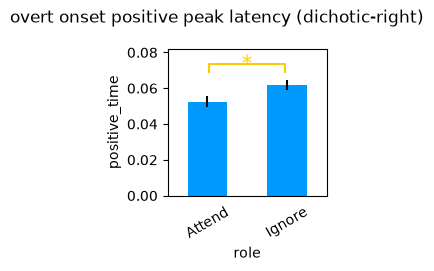

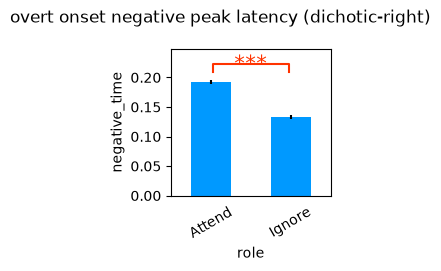

In [25]:
p = plot.Barplot('positive_time', 'role', match='subject', data=data, h=2.5, w=2.5, labels=LABELS_ROLE, corr=False, title='overt onset positive peak latency (dichotic-right)')
p.set_xtick_rotation(30)
p = plot.Barplot('negative_time', 'role', match='subject', data=data, h=2.5, w=2.5, labels=LABELS_ROLE, corr=False, title='overt onset negative peak latency (dichotic-right)')
p.set_xtick_rotation(30)

In [26]:
display(test.pairwise('positive_amp', 'role', match='subject', data=data, corr=False, title='overt onset positive peak amplitude: attend vs. ignore'))
display(test.pairwise('negative_amp', 'role', match='subject', data=data, corr=False, title='overt onset negative peak amplitude: attend vs. ignore'))

,ignore
attend,t12 = 2.91* p = .013


,ignore
attend,t12 = 2.32* p = .039


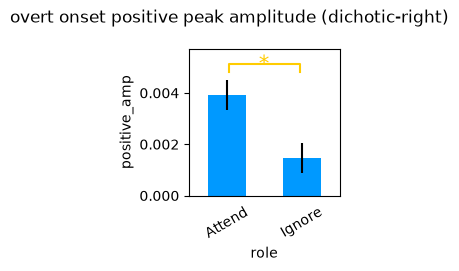

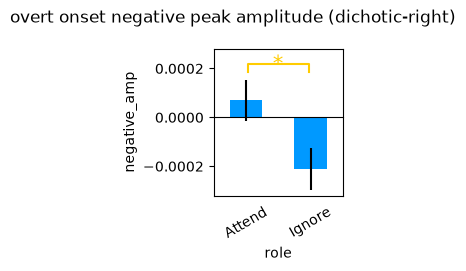

In [27]:
p = plot.Barplot('positive_amp', 'role', match='subject', data=data, h=2.5, w=2.5, labels=LABELS_ROLE, corr=False, title='overt onset positive peak amplitude (dichotic-right)')
p.set_xtick_rotation(30)
p = plot.Barplot('negative_amp', 'role', match='subject', data=data, h=2.5, w=2.5, labels=LABELS_ROLE, corr=False, title='overt onset negative peak amplitude (dichotic-right)')
p.set_xtick_rotation(30)

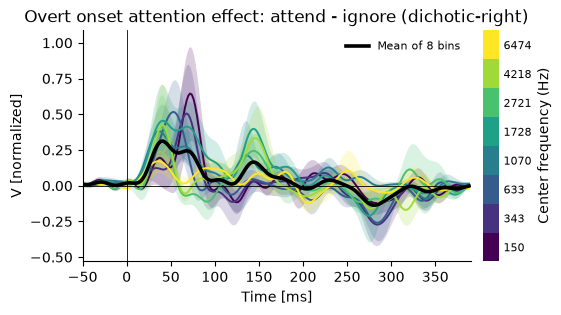

In [28]:
# Overt onset attention effect: attend - ignore (dichotic-right)
p = plot_trf_bins(data_masked, 'gammatone_on_overt_8', 'Overt onset attention effect: attend - ignore (dichotic-right)', subtract='bg_gammatone_on_overt_8')

## Dichotic Right (masked onset)

/Users/joshuaighalo/Github Repositories/cocktail-cortical/analysis/experiment.py:1063: UserWarning: Warning: converting a masked element to nan.
  mean_value = float(data.mean())


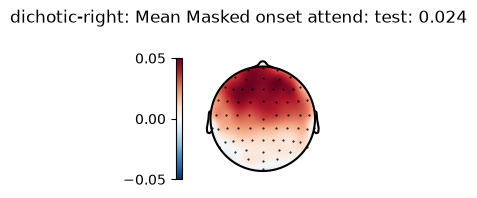

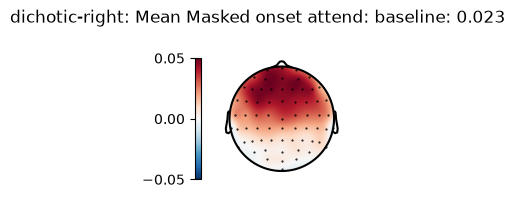

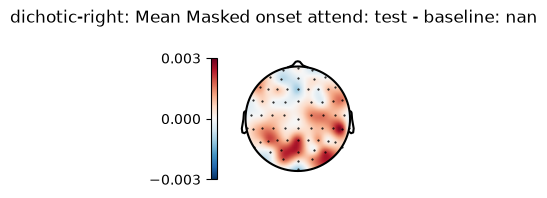

In [29]:
# Masked onset attend unique contribution (dichotic-right)
# Brodbeck et al. 2020 ran this comparison too: attended masked onsets unique contribution, t = 8.42, p < .001 - the strongest of the four masking predictors.
data, diff, result = compute_unique_contribution(FULL_MASKED, masked_onset(ATTEND), 'dichotic-right')
show_topomap_trio(data, diff, result, 'Masked onset attend', 'dichotic-right', masked_onset(ATTEND))

In [30]:
display(result)
ttest = test.TTestOneSample(f'roi_{METRIC}', data=diff, tail=1)
print(f"Masked onset attend (dichotic-right): ROI unique contribution t({ttest.df}) = {ttest.t:.3f}, p = {ttest.p:.4f}")

<TTestRelated 'r', 'model', 'test', 'baseline', 'subject' (n=13), tail=1, samples=8191, pmin=0.05, 1 clusters, p = .652>

Masked onset attend (dichotic-right): ROI unique contribution t(12) = 0.580, p = 0.2862


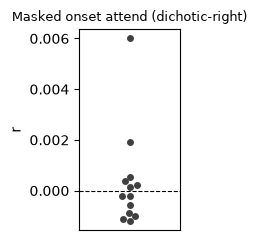

In [31]:
p = show_subject_swarm(diff, 'Masked onset attend', 'dichotic-right')

/Users/joshuaighalo/Github Repositories/cocktail-cortical/analysis/experiment.py:1063: UserWarning: Warning: converting a masked element to nan.
  mean_value = float(data.mean())


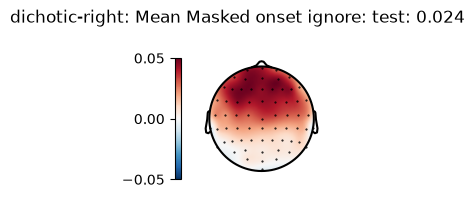

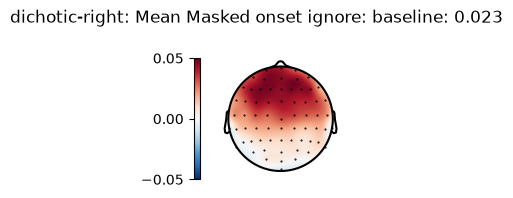

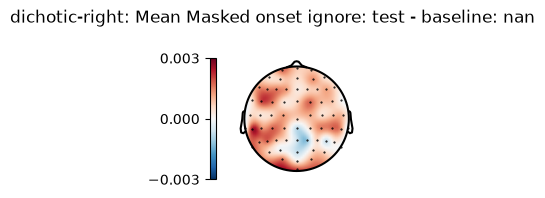

In [32]:
# Masked onset ignore unique contribution (dichotic-right)
# Brodbeck et al. 2020 ran this comparison too: ignored masked onsets unique contribution, t = 5.23, p < .001 - the brain recovers masked information even for the ignored speaker.
data, diff, result = compute_unique_contribution(FULL_MASKED, masked_onset(IGNORE), 'dichotic-right')
show_topomap_trio(data, diff, result, 'Masked onset ignore', 'dichotic-right', masked_onset(IGNORE))

In [33]:
display(result)
ttest = test.TTestOneSample(f'roi_{METRIC}', data=diff, tail=1)
print(f"Masked onset ignore (dichotic-right): ROI unique contribution t({ttest.df}) = {ttest.t:.3f}, p = {ttest.p:.4f}")

<TTestRelated 'r', 'model', 'test', 'baseline', 'subject' (n=13), tail=1, samples=8191, pmin=0.05, 6 clusters, p = .316>

Masked onset ignore (dichotic-right): ROI unique contribution t(12) = 1.505, p = 0.0791


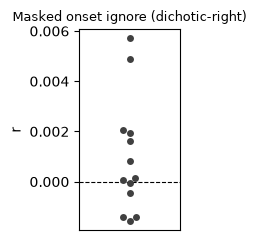

In [34]:
p = show_subject_swarm(diff, 'Masked onset ignore', 'dichotic-right')

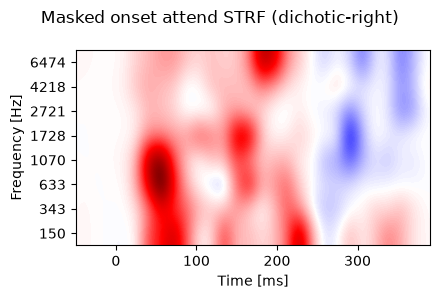

In [35]:
# Masked onset attend STRF (dichotic-right)
strf = extract_strf(data_masked, 'gammatone_on_masked_8')
p = plot.Array(strf * 1e3, title='Masked onset attend STRF (dichotic-right)', interpolation=STRF_INTERPOLATION, xlim=PLOT_WINDOW)

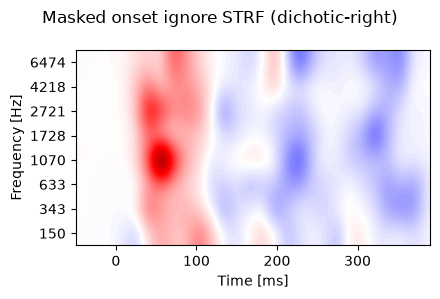

In [36]:
# Masked onset ignore STRF (dichotic-right)
strf = extract_strf(data_masked, 'bg_gammatone_on_masked_8')
p = plot.Array(strf * 1e3, title='Masked onset ignore STRF (dichotic-right)', interpolation=STRF_INTERPOLATION, xlim=PLOT_WINDOW)

In [37]:
# Masked onset attend peak amplitude & timing (dichotic-right)
data = extract_trf(data_masked, 'gammatone_on_masked_8')
data = add_anchored_peak(data, 'positive', MASKED_POSITIVE_PEAK_WINDOW, kind='max')
data = add_anchored_peak(data, 'negative', MASKED_NEGATIVE_PEAK_WINDOW, kind='min')
print(f"Masked onset attend (dichotic-right) positive peak: {data['positive_time'].mean() * 1e3:.0f} ms, amp {data['positive_amp'].mean():.4g}")
print(f"Masked onset attend (dichotic-right) negative peak: {data['negative_time'].mean() * 1e3:.0f} ms, amp {data['negative_amp'].mean():.4g}")

Masked onset attend (dichotic-right) positive peak: 54 ms, amp 0.002175
Masked onset attend (dichotic-right) negative peak: 107 ms, amp -0.0004133


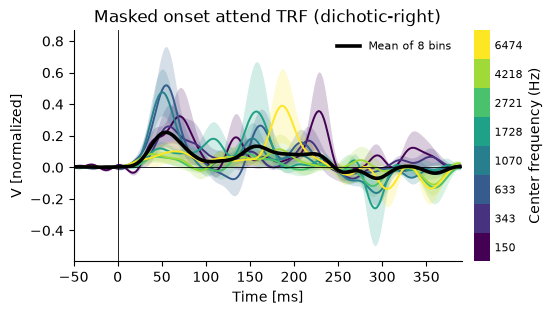

In [38]:
# Masked onset attend TRF per frequency bin (dichotic-right)
p = plot_trf_bins(data_masked, 'gammatone_on_masked_8', 'Masked onset attend TRF (dichotic-right)')

In [39]:
# Masked onset ignore peak amplitude & timing (dichotic-right)
data = extract_trf(data_masked, 'bg_gammatone_on_masked_8')
data = add_anchored_peak(data, 'positive', MASKED_POSITIVE_PEAK_WINDOW, kind='max')
data = add_anchored_peak(data, 'negative', MASKED_NEGATIVE_PEAK_WINDOW, kind='min')
print(f"Masked onset ignore (dichotic-right) positive peak: {data['positive_time'].mean() * 1e3:.0f} ms, amp {data['positive_amp'].mean():.4g}")
print(f"Masked onset ignore (dichotic-right) negative peak: {data['negative_time'].mean() * 1e3:.0f} ms, amp {data['negative_amp'].mean():.4g}")

Masked onset ignore (dichotic-right) positive peak: 61 ms, amp 0.00243
Masked onset ignore (dichotic-right) negative peak: 143 ms, amp -0.0007034


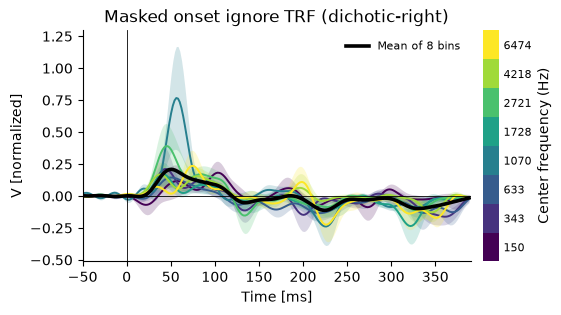

In [40]:
# Masked onset ignore TRF per frequency bin (dichotic-right)
p = plot_trf_bins(data_masked, 'bg_gammatone_on_masked_8', 'Masked onset ignore TRF (dichotic-right)')

In [41]:
# Masked onset peak comparison across attend and ignore (dichotic-right)
dss = []
for role_name, column in (('attend', 'gammatone_on_masked_8'), ('ignore', 'bg_gammatone_on_masked_8')):
    ds = extract_trf(data_masked, column)
    ds[:, 'role'] = role_name
    dss.append(ds)
data = combine(dss)
data = add_anchored_peak(data, 'positive', MASKED_POSITIVE_PEAK_WINDOW, kind='max', by='role')
data = add_anchored_peak(data, 'negative', MASKED_NEGATIVE_PEAK_WINDOW, kind='min', by='role')

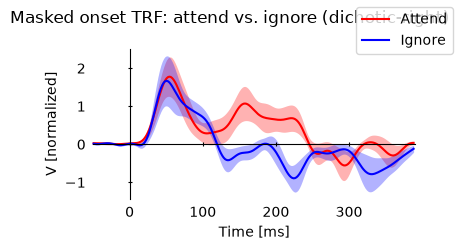

In [42]:
# The masked onset TRF waveform attend/ignore were each just measured
# from, overlaid so their shape and relative timing are visible
# directly, not just as extracted peak numbers below.
p = plot.UTSStat('trf_sm*1e3', 'role', data=data, frame='t', h=2.5, w=4, xlim=PLOT_WINDOW,
                  title='Masked onset TRF: attend vs. ignore (dichotic-right)', labels={'attend': 'Attend', 'ignore': 'Ignore'}, colors={'attend': 'red', 'ignore': 'blue'})

In [43]:
print_peak_table(data, 'positive', 'role')
print_peak_table(data, 'negative', 'role')


positive peak
subject   role         time (ms)           amp
01        attend              41     0.0006979
02        attend              50      0.001607
03        attend              78      0.000261
04        attend              62      0.003144
05        attend              41      0.004039
06        attend              50     0.0007229
07        attend              52      0.001515
08        attend              54       0.00661
09        attend              52     0.0005215
10        attend              45       0.00189
11        attend              64      0.001676
12        attend              45     4.017e-05
13        attend              70      0.005555
01        ignore              74     0.0009547
02        ignore              74     0.0002925
03        ignore              46     0.0004386
04        ignore              66     0.0001925
05        ignore              52      0.006029
06        ignore              41      0.005911
07        ignore              74      0.00156

In [44]:
display(test.pairwise('positive_time', 'role', match='subject', data=data, corr=False, title='masked onset positive peak latency: attend vs. ignore'))
display(test.pairwise('negative_time', 'role', match='subject', data=data, corr=False, title='masked onset negative peak latency: attend vs. ignore'))

,ignore
attend,t12 = -1.34 p = .206


,ignore
attend,t12 = -4.62*** p < .001


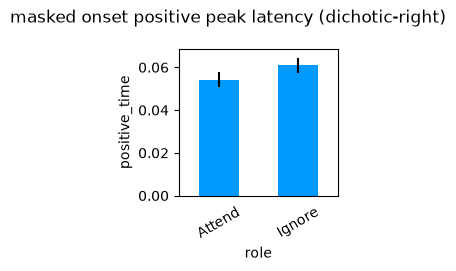

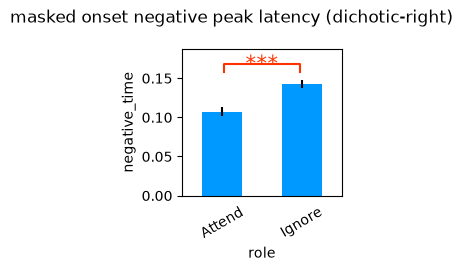

In [45]:
p = plot.Barplot('positive_time', 'role', match='subject', data=data, h=2.5, w=2.5, labels=LABELS_ROLE, corr=False, title='masked onset positive peak latency (dichotic-right)')
p.set_xtick_rotation(30)
p = plot.Barplot('negative_time', 'role', match='subject', data=data, h=2.5, w=2.5, labels=LABELS_ROLE, corr=False, title='masked onset negative peak latency (dichotic-right)')
p.set_xtick_rotation(30)

In [46]:
display(test.pairwise('positive_amp', 'role', match='subject', data=data, corr=False, title='masked onset positive peak amplitude: attend vs. ignore'))
display(test.pairwise('negative_amp', 'role', match='subject', data=data, corr=False, title='masked onset negative peak amplitude: attend vs. ignore'))

,ignore
attend,t12 = -0.30 p = .766


,ignore
attend,t12 = 0.93 p = .370


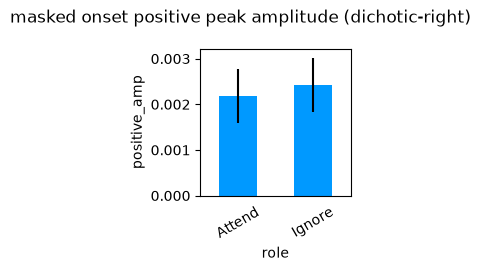

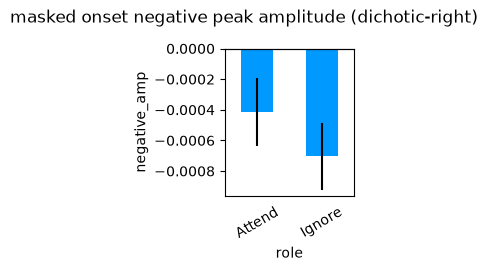

In [47]:
p = plot.Barplot('positive_amp', 'role', match='subject', data=data, h=2.5, w=2.5, labels=LABELS_ROLE, corr=False, title='masked onset positive peak amplitude (dichotic-right)')
p.set_xtick_rotation(30)
p = plot.Barplot('negative_amp', 'role', match='subject', data=data, h=2.5, w=2.5, labels=LABELS_ROLE, corr=False, title='masked onset negative peak amplitude (dichotic-right)')
p.set_xtick_rotation(30)

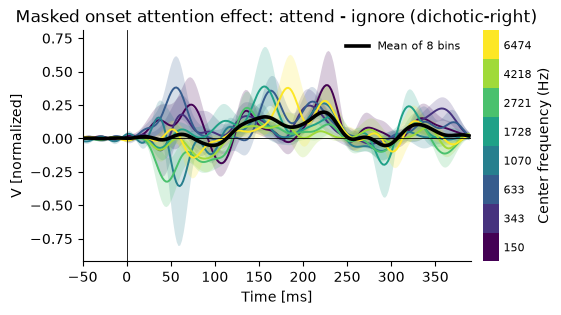

In [48]:
# Masked onset attention effect: attend - ignore (dichotic-right)
p = plot_trf_bins(data_masked, 'gammatone_on_masked_8', 'Masked onset attention effect: attend - ignore (dichotic-right)', subtract='bg_gammatone_on_masked_8')

In [49]:
# Overt vs. masked peak comparison, attend (dichotic-right)
# Brodbeck et al. 2020 ran this comparison too: attended overt 72ms vs. attended masked 91ms (t=2.85,p=.009); combined (not stream-split) late negative peak, overt 133ms vs. masked 182ms (t=4.45,p<.001).
dss = []
for masking, column in (('overt', 'gammatone_on_overt_8'), ('masked', 'gammatone_on_masked_8')):
    ds = extract_trf(data_masked, column)
    ds[:, 'masking'] = masking
    dss.append(ds)
data = combine(dss)
data = add_anchored_peak(data, 'positive', MASKED_POSITIVE_PEAK_WINDOW, kind='max', by='masking')
data = add_anchored_peak(data, 'negative', MASKED_NEGATIVE_PEAK_WINDOW, kind='min', by='masking')

/Users/joshuaighalo/Github Repositories/cocktail-cortical/analysis/experiment.py:1798: UserWarning: negative anchor (overt) at 199 ms is on the edge of the search window (0.04, 0.2)
  warnings.warn(f"{name} anchor ({label}) at {times[i] * 1e3:.0f} ms is on the edge of the search window {window}")


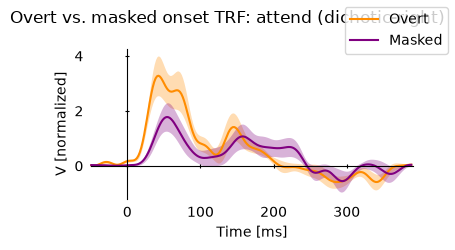

In [50]:
# Overt and masked onset TRFs of the attended speaker, overlaid
p = plot.UTSStat('trf_sm*1e3', 'masking', data=data, frame='t', h=2.5, w=4, xlim=PLOT_WINDOW,
                  title='Overt vs. masked onset TRF: attend (dichotic-right)', labels=LABELS_MASKING, colors=COLORS_MASKING)

In [51]:
print_peak_table(data, 'positive', 'masking')
print_peak_table(data, 'negative', 'masking')


positive peak
subject   masking      time (ms)           amp
01        overt               46     0.0008426
02        overt               56      0.004289
03        overt               41      0.001667
04        overt               62     0.0004542
05        overt               41      0.007624
06        overt               43      0.001422
07        overt               66       0.00152
08        overt               45      0.005802
09        overt               66      0.008882
10        overt               43      0.007422
11        overt               66      0.003017
12        overt               41      0.005783
13        overt               66       0.00229
01        masked              41     0.0006979
02        masked              50      0.001607
03        masked              78      0.000261
04        masked              62      0.003144
05        masked              41      0.004039
06        masked              50     0.0007229
07        masked              52      0.00151

In [52]:
display(test.pairwise('positive_time', 'masking', match='subject', data=data, corr=False, title='attend positive peak latency: overt vs. masked'))
display(test.pairwise('negative_time', 'masking', match='subject', data=data, corr=False, title='attend negative peak latency: overt vs. masked'))

,masked
overt,t12 = -0.51 p = .621


,masked
overt,t12 = 13.57*** p < .001


In [53]:
display(test.pairwise('positive_amp', 'masking', match='subject', data=data, corr=False, title='attend positive peak amplitude: overt vs. masked'))
display(test.pairwise('negative_amp', 'masking', match='subject', data=data, corr=False, title='attend negative peak amplitude: overt vs. masked'))

,masked
overt,t12 = 1.87 p = .086


,masked
overt,t12 = 2.02 p = .066


In [54]:
# Overt vs. masked peak comparison, ignore (dichotic-right)
# Brodbeck et al. 2020 ran this comparison too: ignored overt 83ms vs. ignored masked 97ms (t=6.11,p<.001); combined (not stream-split) late negative peak, overt 133ms vs. masked 182ms (t=4.45,p<.001).
dss = []
for masking, column in (('overt', 'bg_gammatone_on_overt_8'), ('masked', 'bg_gammatone_on_masked_8')):
    ds = extract_trf(data_masked, column)
    ds[:, 'masking'] = masking
    dss.append(ds)
data = combine(dss)
data = add_anchored_peak(data, 'positive', MASKED_POSITIVE_PEAK_WINDOW, kind='max', by='masking')
data = add_anchored_peak(data, 'negative', MASKED_NEGATIVE_PEAK_WINDOW, kind='min', by='masking')

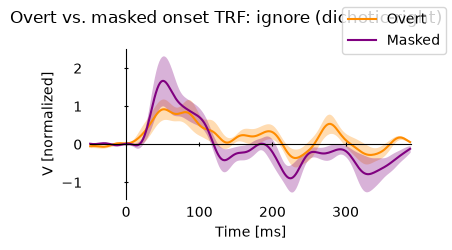

In [55]:
# Overt and masked onset TRFs of the ignored speaker, overlaid
p = plot.UTSStat('trf_sm*1e3', 'masking', data=data, frame='t', h=2.5, w=4, xlim=PLOT_WINDOW,
                  title='Overt vs. masked onset TRF: ignore (dichotic-right)', labels=LABELS_MASKING, colors=COLORS_MASKING)

In [56]:
print_peak_table(data, 'positive', 'masking')
print_peak_table(data, 'negative', 'masking')


positive peak
subject   masking      time (ms)           amp
01        overt               54     0.0006277
02        overt               76      0.001144
03        overt               76     0.0003953
04        overt               58       0.00185
05        overt               56      0.002913
06        overt               41     0.0004993
07        overt               76      0.001955
08        overt               50      0.001152
09        overt               72     0.0002443
10        overt               56     0.0005941
11        overt               43      0.003646
12        overt               76      0.002781
13        overt               70       0.00126
01        masked              74     0.0009547
02        masked              74     0.0002925
03        masked              46     0.0004386
04        masked              66     0.0001925
05        masked              52      0.006029
06        masked              41      0.005911
07        masked              74      0.00156

In [57]:
display(test.pairwise('positive_time', 'masking', match='subject', data=data, corr=False, title='ignore positive peak latency: overt vs. masked'))
display(test.pairwise('negative_time', 'masking', match='subject', data=data, corr=False, title='ignore negative peak latency: overt vs. masked'))

,masked
overt,t12 = 0.27 p = .788


,masked
overt,t12 = -1.66 p = .122


In [58]:
display(test.pairwise('positive_amp', 'masking', match='subject', data=data, corr=False, title='ignore positive peak amplitude: overt vs. masked'))
display(test.pairwise('negative_amp', 'masking', match='subject', data=data, corr=False, title='ignore negative peak amplitude: overt vs. masked'))

,masked
overt,t12 = -1.37 p = .195


,masked
overt,t12 = 1.78 p = .101


In [59]:
# Stream x masking interaction on peak amplitude (dichotic-right)
# Brodbeck et al. 2020 ran this comparison too: stream x masking interaction, F(1,25) = 24.45, p < .001 - overt onsets show no early attention effect, masked onsets do.
dss = []
for stream_name, is_attend in (('attend', True), ('ignore', False)):
    for masking_name in ('overt', 'masked'):
        prefix = '' if is_attend else 'bg_'
        column = f'{prefix}gammatone_on_{masking_name}_8'
        ds = extract_trf(data_masked, column)
        ds[:, 'stream'] = stream_name
        ds[:, 'masking'] = masking_name
        dss.append(ds)
data = combine(dss)
data = add_anchored_peak(data, 'positive', MASKED_POSITIVE_PEAK_WINDOW, kind='max', by=('stream', 'masking'))
display(test.ANOVA('positive_amp', 'stream * masking * subject', data=data, title='stream x masking interaction (dichotic-right)'))

<ANOVA: positive_amp ~ stream + masking + stream x masking + subject + stream x subject + masking x subject + stream x masking x subject
  
  stream x masking interaction (dichotic-right)
  
                       SS   df     MS   MS(denom)   df(denom)         F      p
  ----------------------------------------------------------------------------
  stream             0.00    1   0.00        0.00          12   4.52      .055
  masking            0.00    1   0.00        0.00          12   0.63      .444
  stream x masking   0.00    1   0.00        0.00          12   4.20      .063
  ----------------------------------------------------------------------------
  Total              0.00   51
>

## Dichotic Right (intensity-level control)

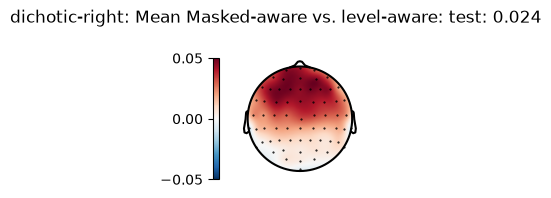

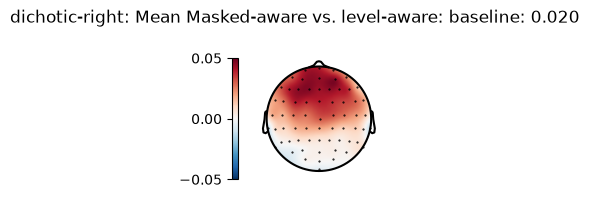

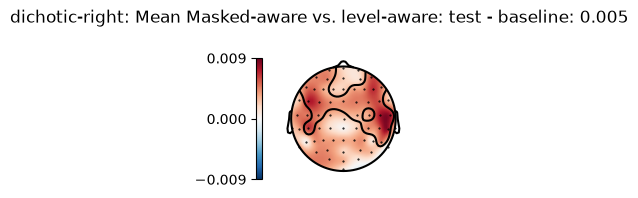

In [60]:
# Masked-aware vs. level-aware (dichotic-right)
# Brodbeck et al. 2020 ran this comparison too: the ignored-speaker-aware model still beat the loudness-only model, t = 9.21, p < .001 - the masking effect isn't just about volume.
data, diff, result = compute_direct_comparison(FULL_MASKED, LEVEL_AWARE, 'dichotic-right')
show_topomap_trio(data, diff, result, 'Masked-aware vs. level-aware', 'dichotic-right', None)

In [61]:
display(result)
ttest = test.TTestOneSample(f'roi_{METRIC}', data=diff, tail=1)
print(f"Masked-aware vs. level-aware (dichotic-right): ROI model comparison t({ttest.df}) = {ttest.t:.3f}, p = {ttest.p:.4f}")

<TTestRelated 'r', 'model', 'test', 'baseline', 'subject' (n=13), tail=1, samples=8191, pmin=0.05, 3 clusters, p = .008>

Masked-aware vs. level-aware (dichotic-right): ROI model comparison t(12) = 2.971, p = 0.0058


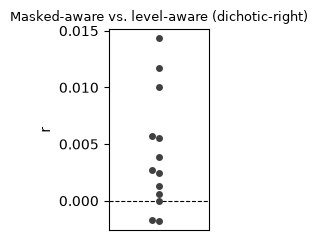

In [62]:
p = show_subject_swarm(diff, 'Masked-aware vs. level-aware', 'dichotic-right')